# 综合实验 1 文本分析 · 任务 9：全部 / 好评 / 差评词频与词云

- 词频来自 `src/build_tokens.py` 全量分词时顺带统计的 3 个 Counter（无需二次扫描）；
- 词云字体：`C:/Windows/Fonts/msyh.ttc`（微软雅黑）；
- all = 4,107,199 条；好评 = 4–5 星（1,721,499 条）；差评 = 1–2 星（220,947 条）。

In [1]:
import sys, pickle
import numpy as np
import pandas as pd
from IPython.display import Image, display

SRC = "D:/DSH-Workspaces/数据科学/综合实验1/src"
sys.path.insert(0, SRC)
from config import CACHE, TAB
import viz_utils

viz_utils.set_cn_font()
pd.set_option("display.width", 160)

def load_counter(name):
    with open(CACHE / name, "rb") as f:
        return pickle.load(f)

cnt_all = load_counter("cnt_all.pkl")
cnt_good = load_counter("cnt_good.pkl")
cnt_bad = load_counter("cnt_bad.pkl")
print("词表规模: all=%d | 好评=%d | 差评=%d" % (len(cnt_all), len(cnt_good), len(cnt_bad)))
print("词条总量: all=%d | 好评=%d | 差评=%d" % (
    sum(cnt_all.values()), sum(cnt_good.values()), sum(cnt_bad.values())))

词表规模: all=1110539 | 好评=671623 | 差评=255008
词条总量: all=125009428 | 好评=53445349 | 差评=8506327


In [2]:
def top_table(counter, topn=20, name="词频"):
    t = pd.DataFrame(counter.most_common(topn), columns=["词", name])
    t.index = np.arange(1, len(t) + 1)
    return t

print("=== all Top20 ===")
display(top_table(cnt_all, 20, "all频次"))
print("=== 好评 Top20 ===")
display(top_table(cnt_good, 20, "好评频次"))
print("=== 差评 Top20 ===")
display(top_table(cnt_bad, 20, "差评频次"))

=== all Top20 ===


,词,all频次
1,不错,2346281
2,味道,2112800
3,喜欢,1283958
4,环境,895425
5,好吃,844717
6,价格,639336
7,服务员,616303
8,服务,584087
9,朋友,577702
10,口味,509630


=== 好评 Top20 ===


,词,好评频次
1,不错,1159917
2,味道,852943
3,喜欢,657168
4,好吃,398809
5,环境,389457
6,价格,263009
7,朋友,261074
8,服务,241964
9,口味,207665
10,他家,204204


=== 差评 Top20 ===


,词,差评频次
1,服务员,102568
2,味道,97540
3,服务,57467
4,不错,40206
5,结果,40025
6,环境,38151
7,实在,31750
8,难吃,31618
9,价格,30927
10,朋友,30613


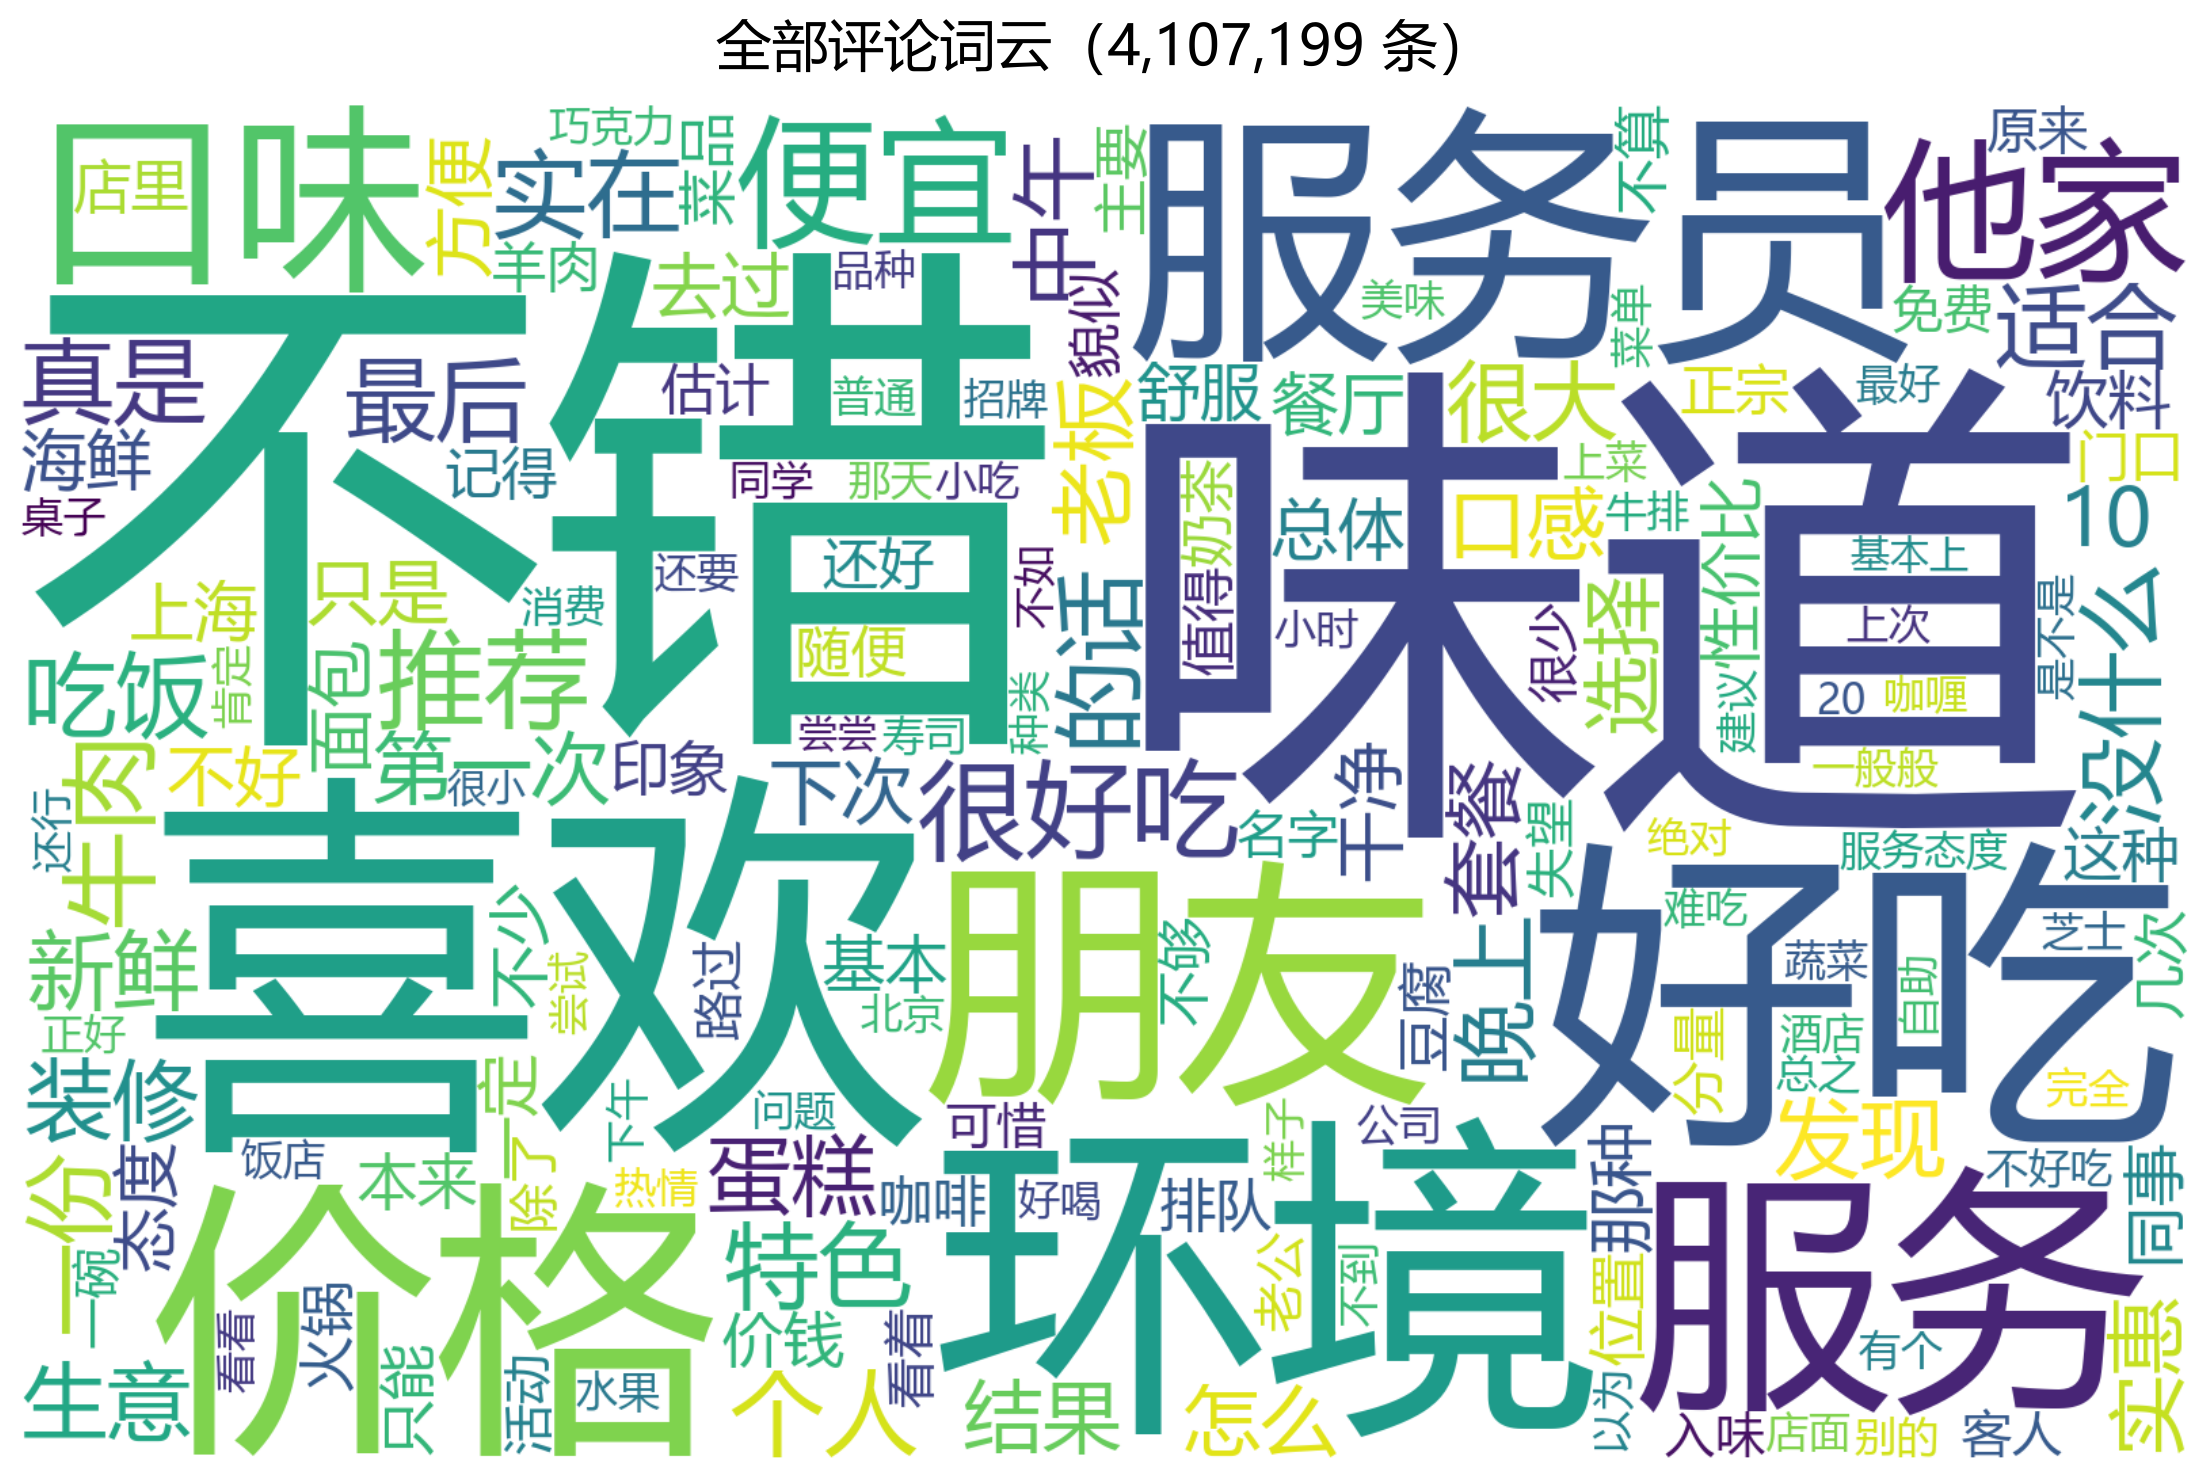

In [3]:
fig = viz_utils.plot_wordcloud(cnt_all, "全部评论词云（4,107,199 条）",
                               "fig09_all_wordcloud.png", max_words=160, cmap="viridis")
display(Image(filename=str(fig)))

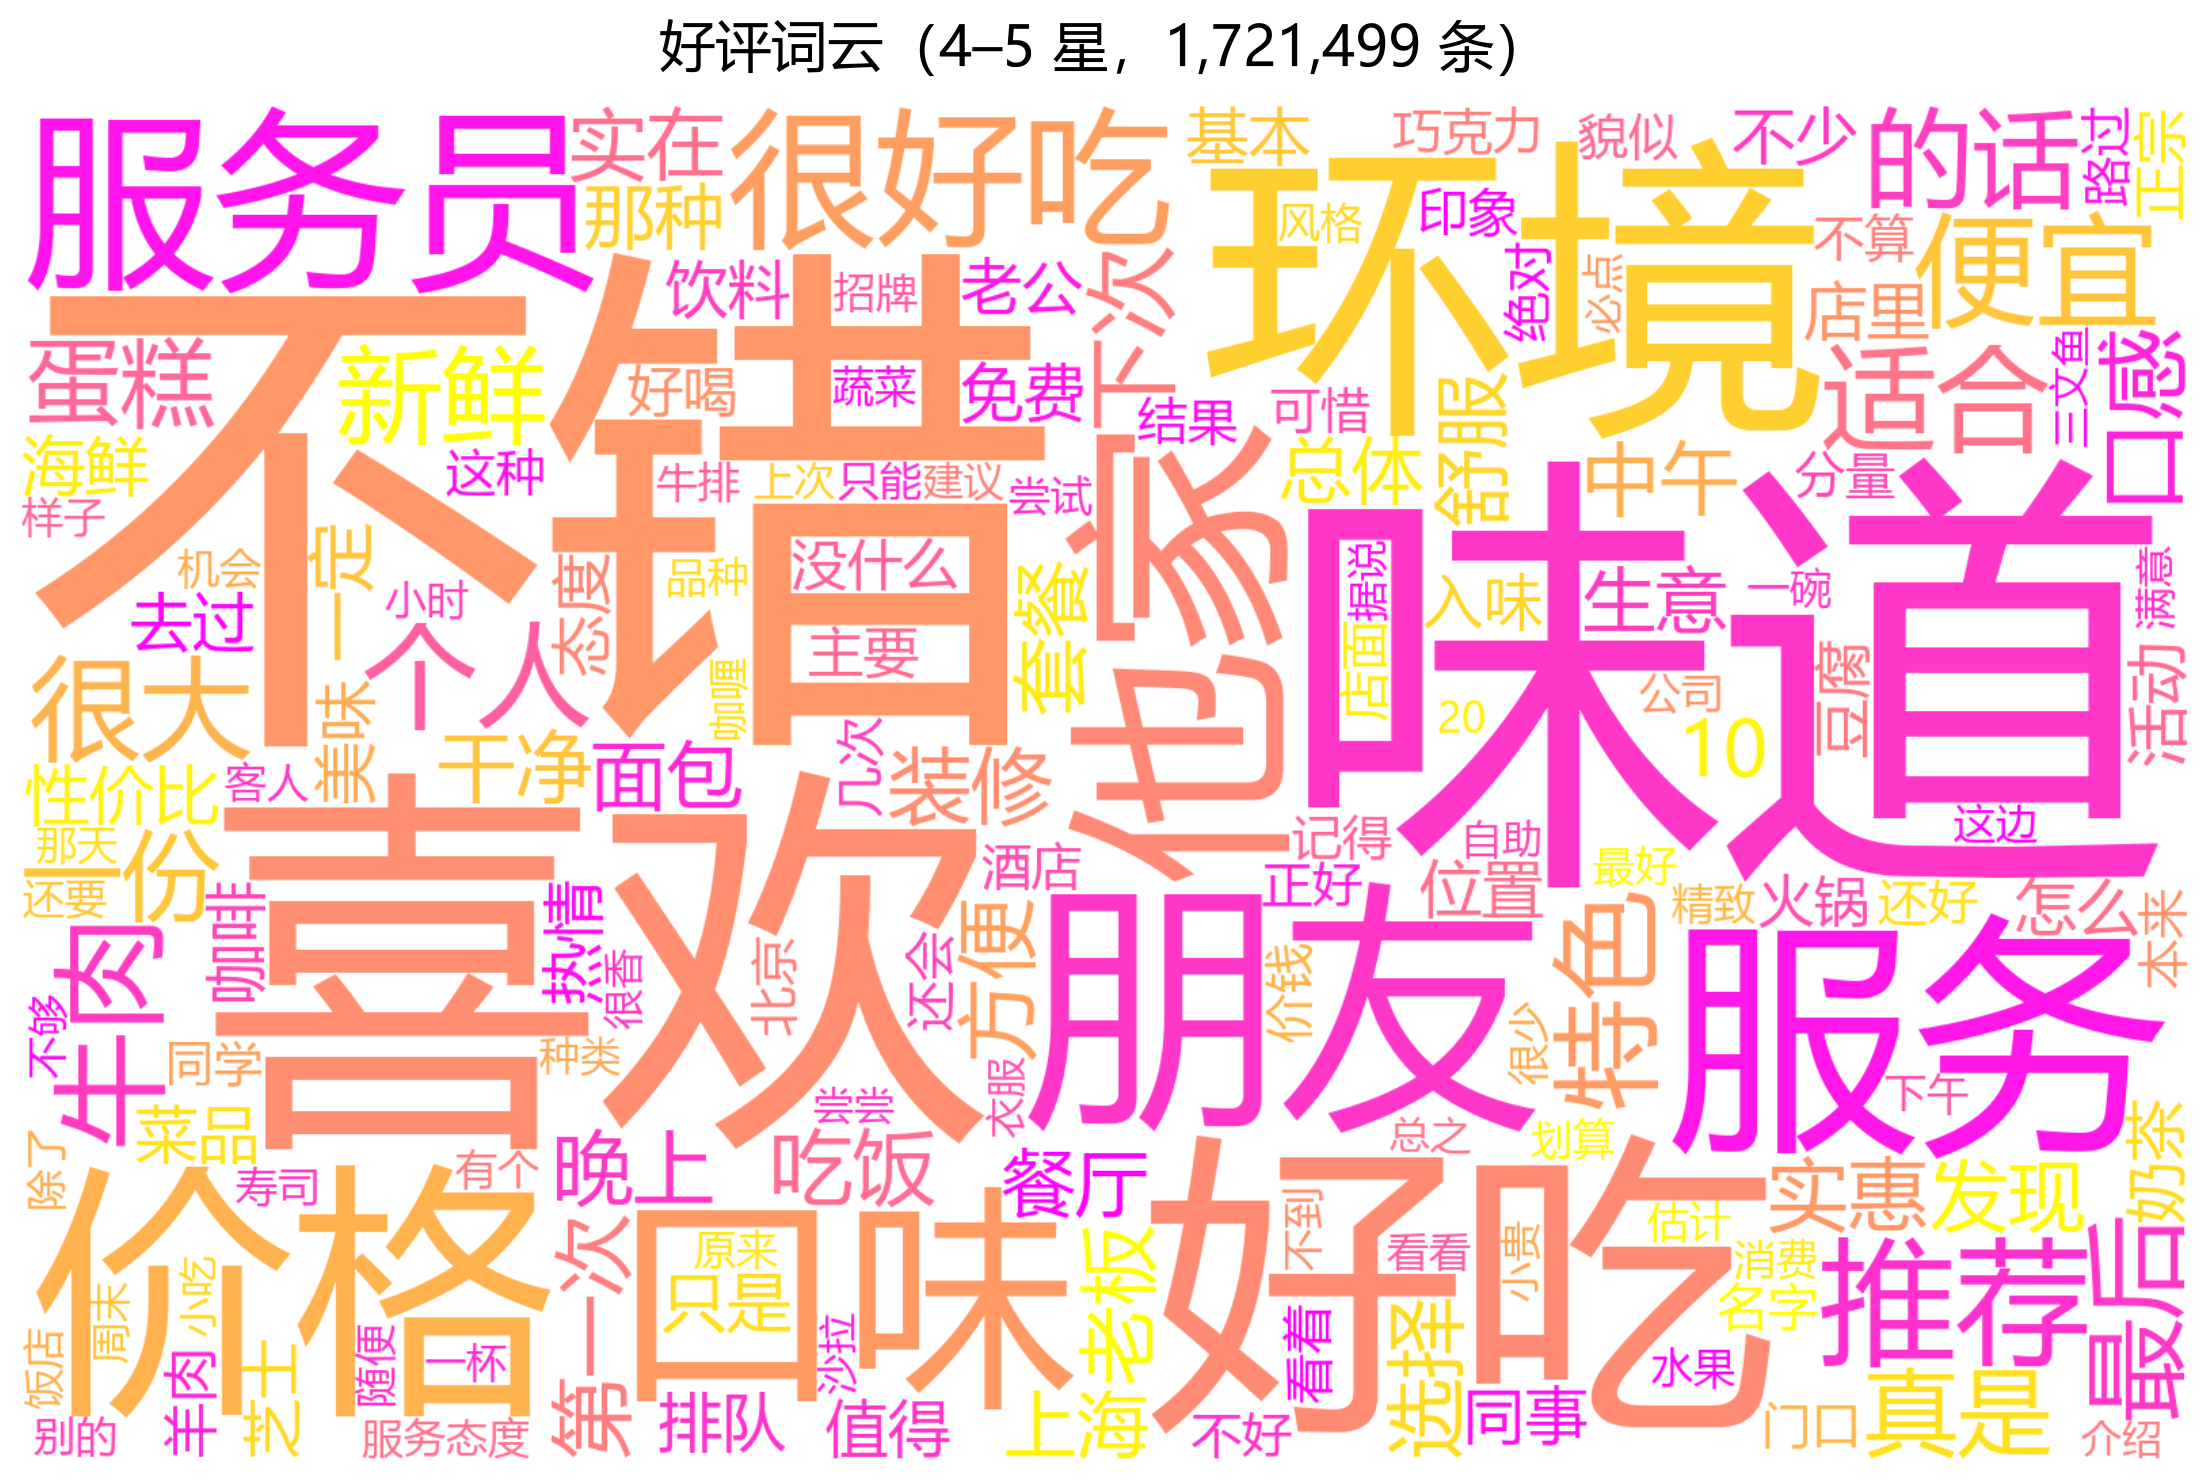

In [4]:
fig = viz_utils.plot_wordcloud(cnt_good, "好评词云（4–5 星，1,721,499 条）",
                               "fig09_good_wordcloud.png", max_words=160, cmap="spring")
display(Image(filename=str(fig)))

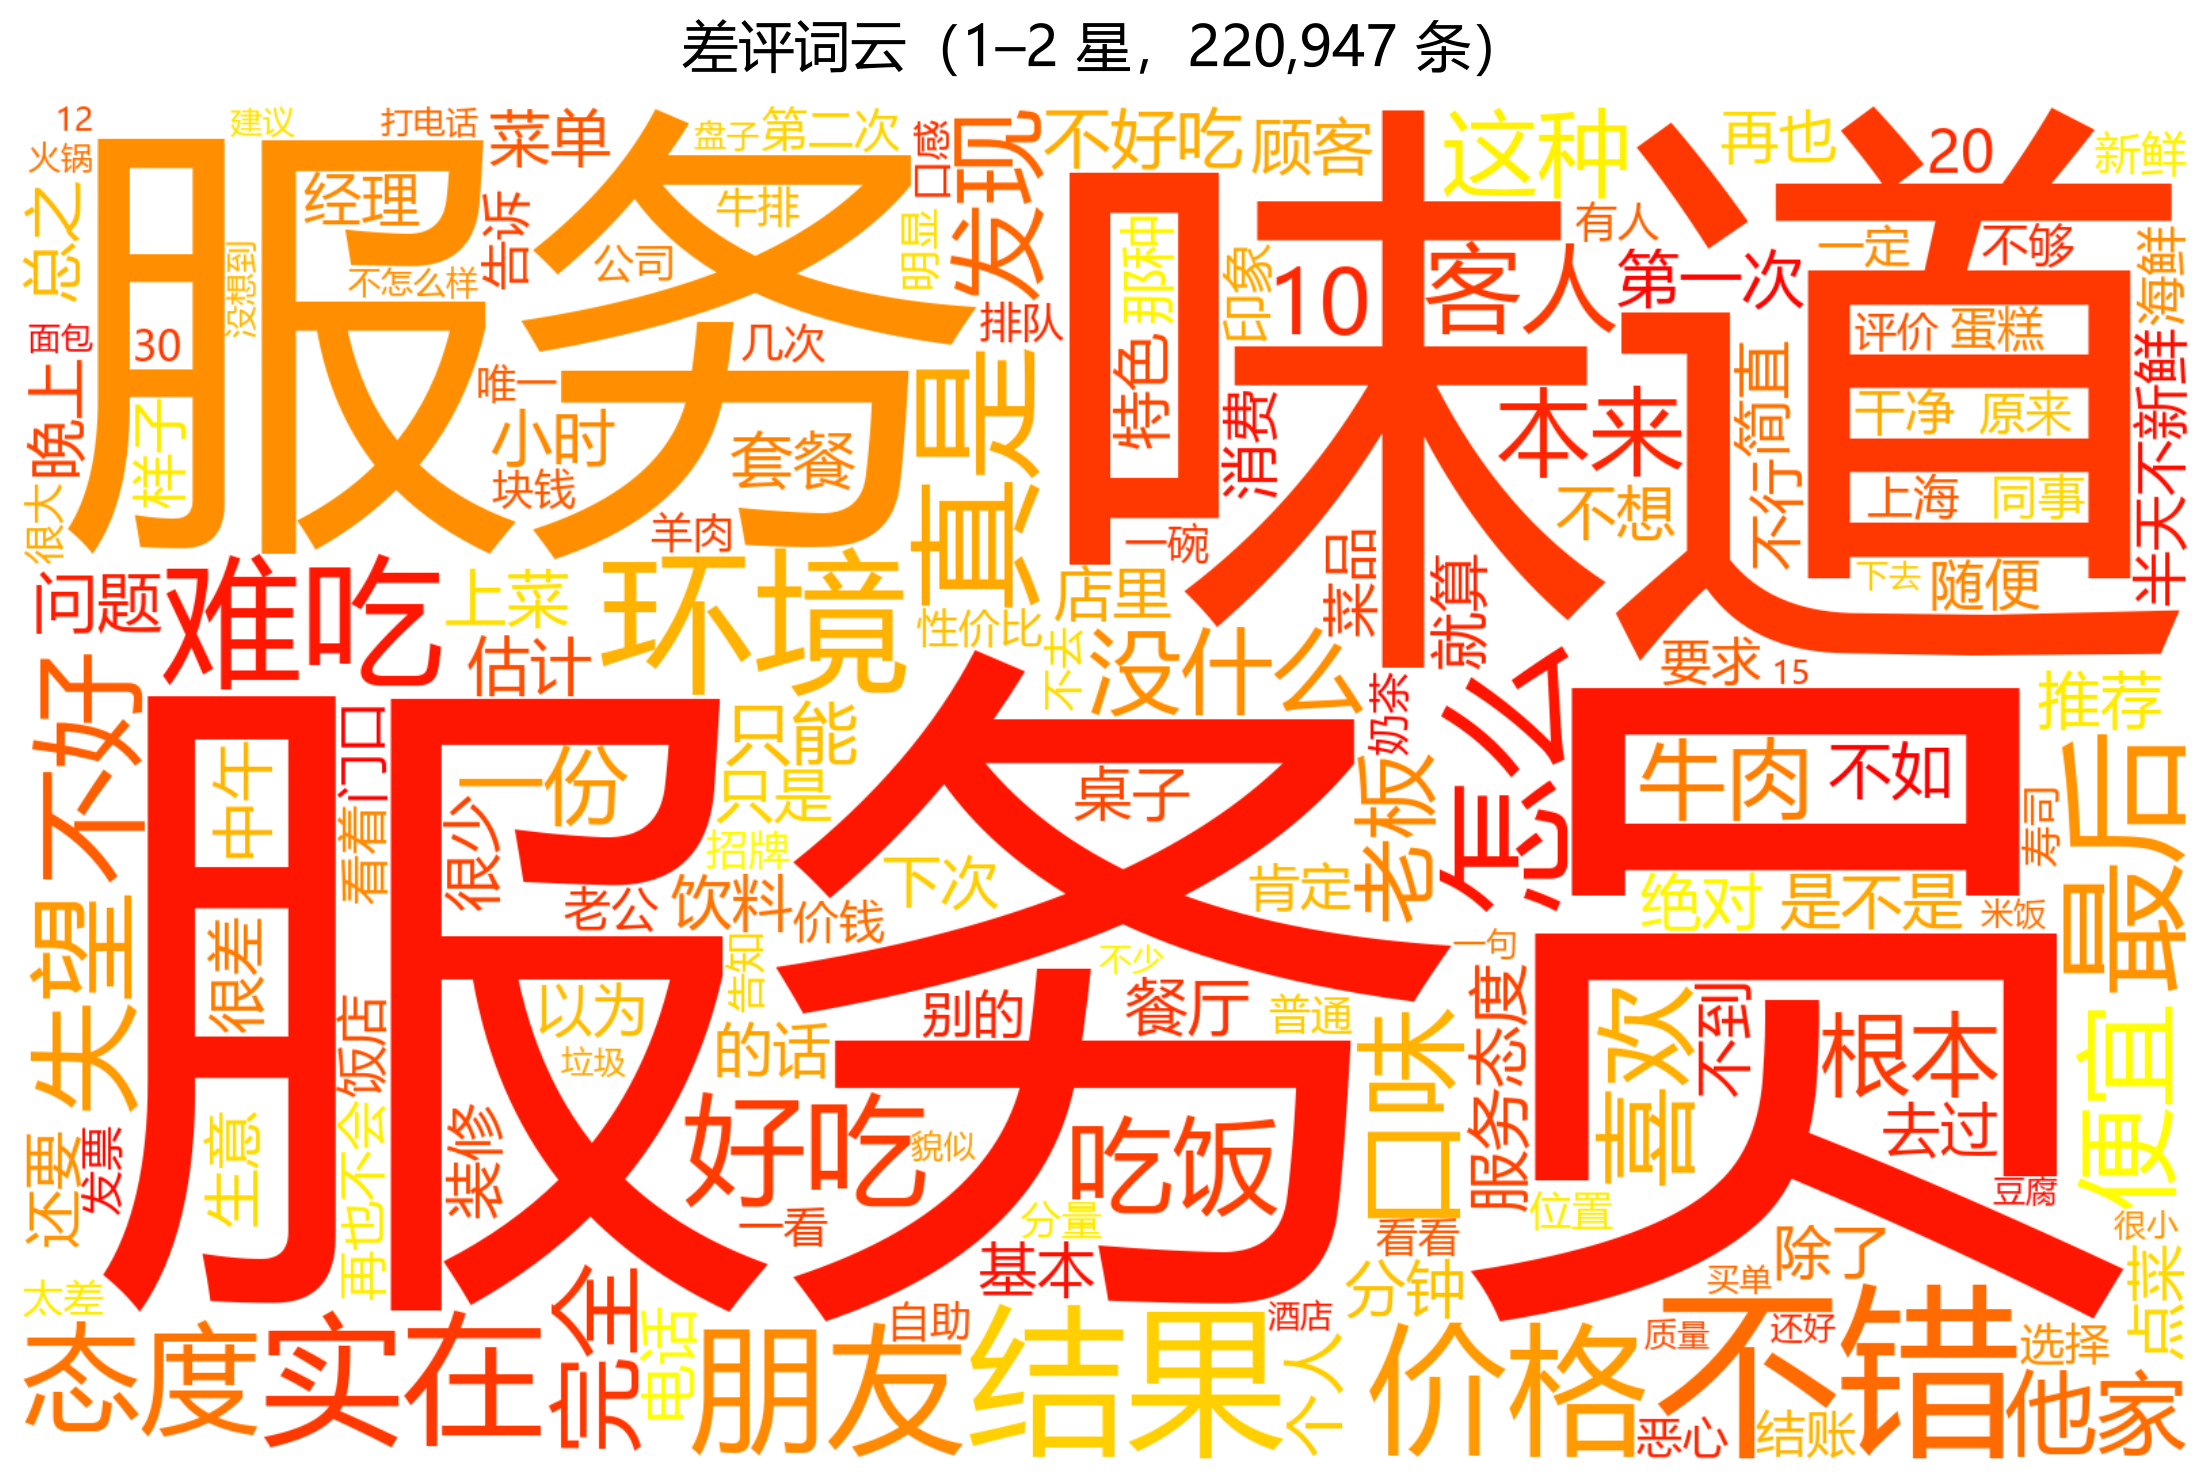

In [5]:
fig = viz_utils.plot_wordcloud(cnt_bad, "差评词云（1–2 星，220,947 条）",
                               "fig09_bad_wordcloud.png", max_words=160, cmap="autumn")
display(Image(filename=str(fig)))

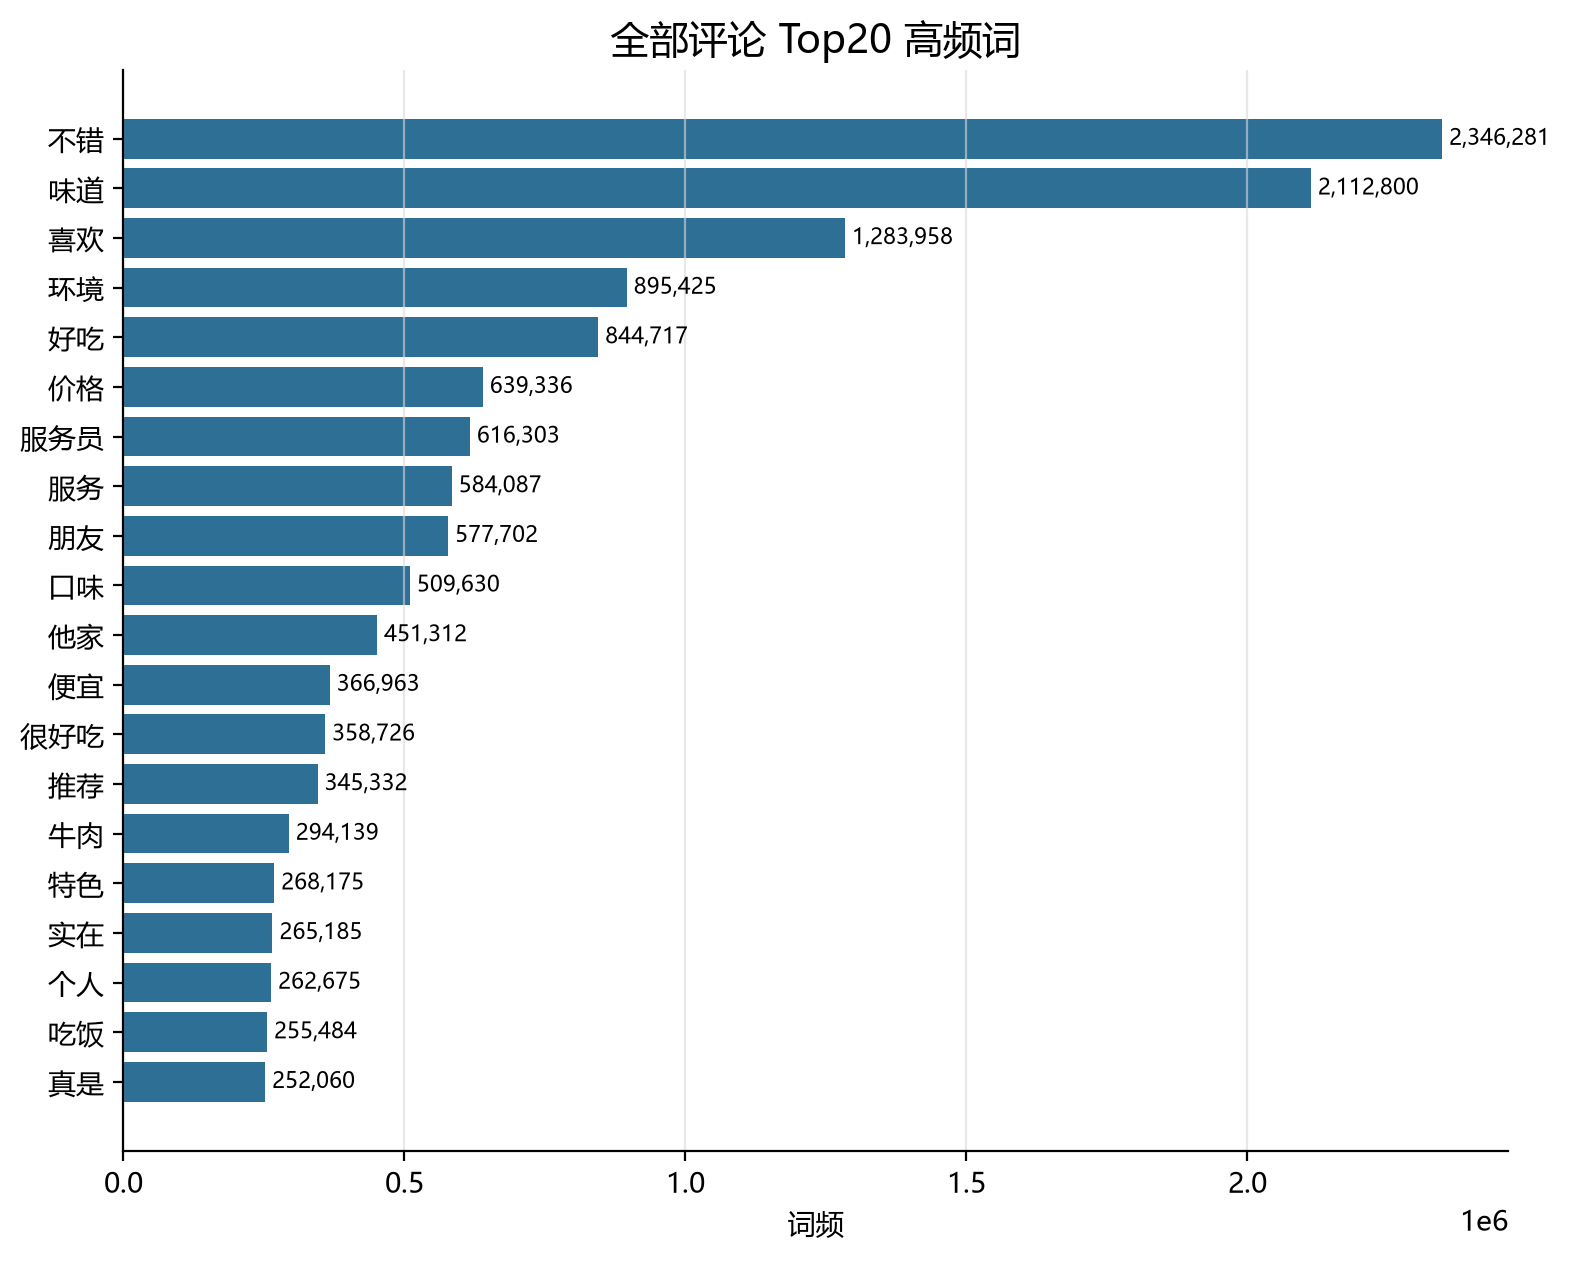

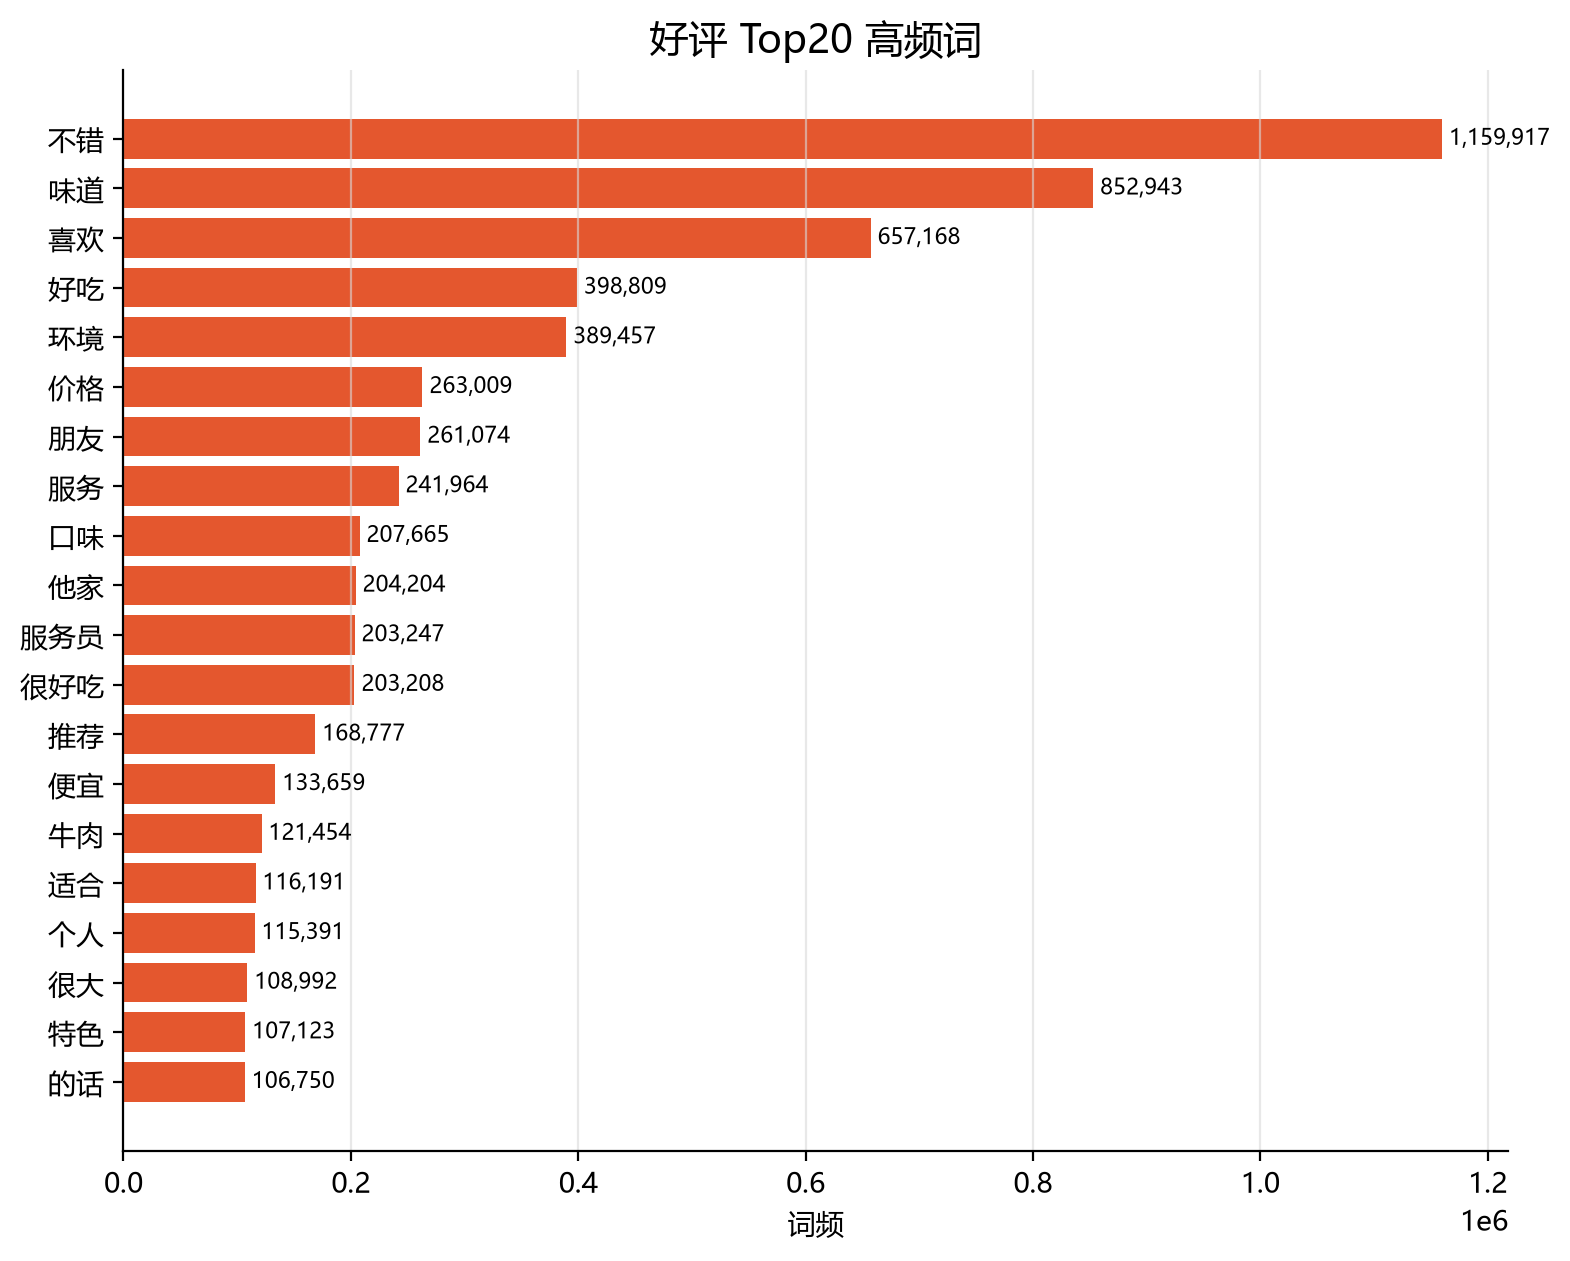

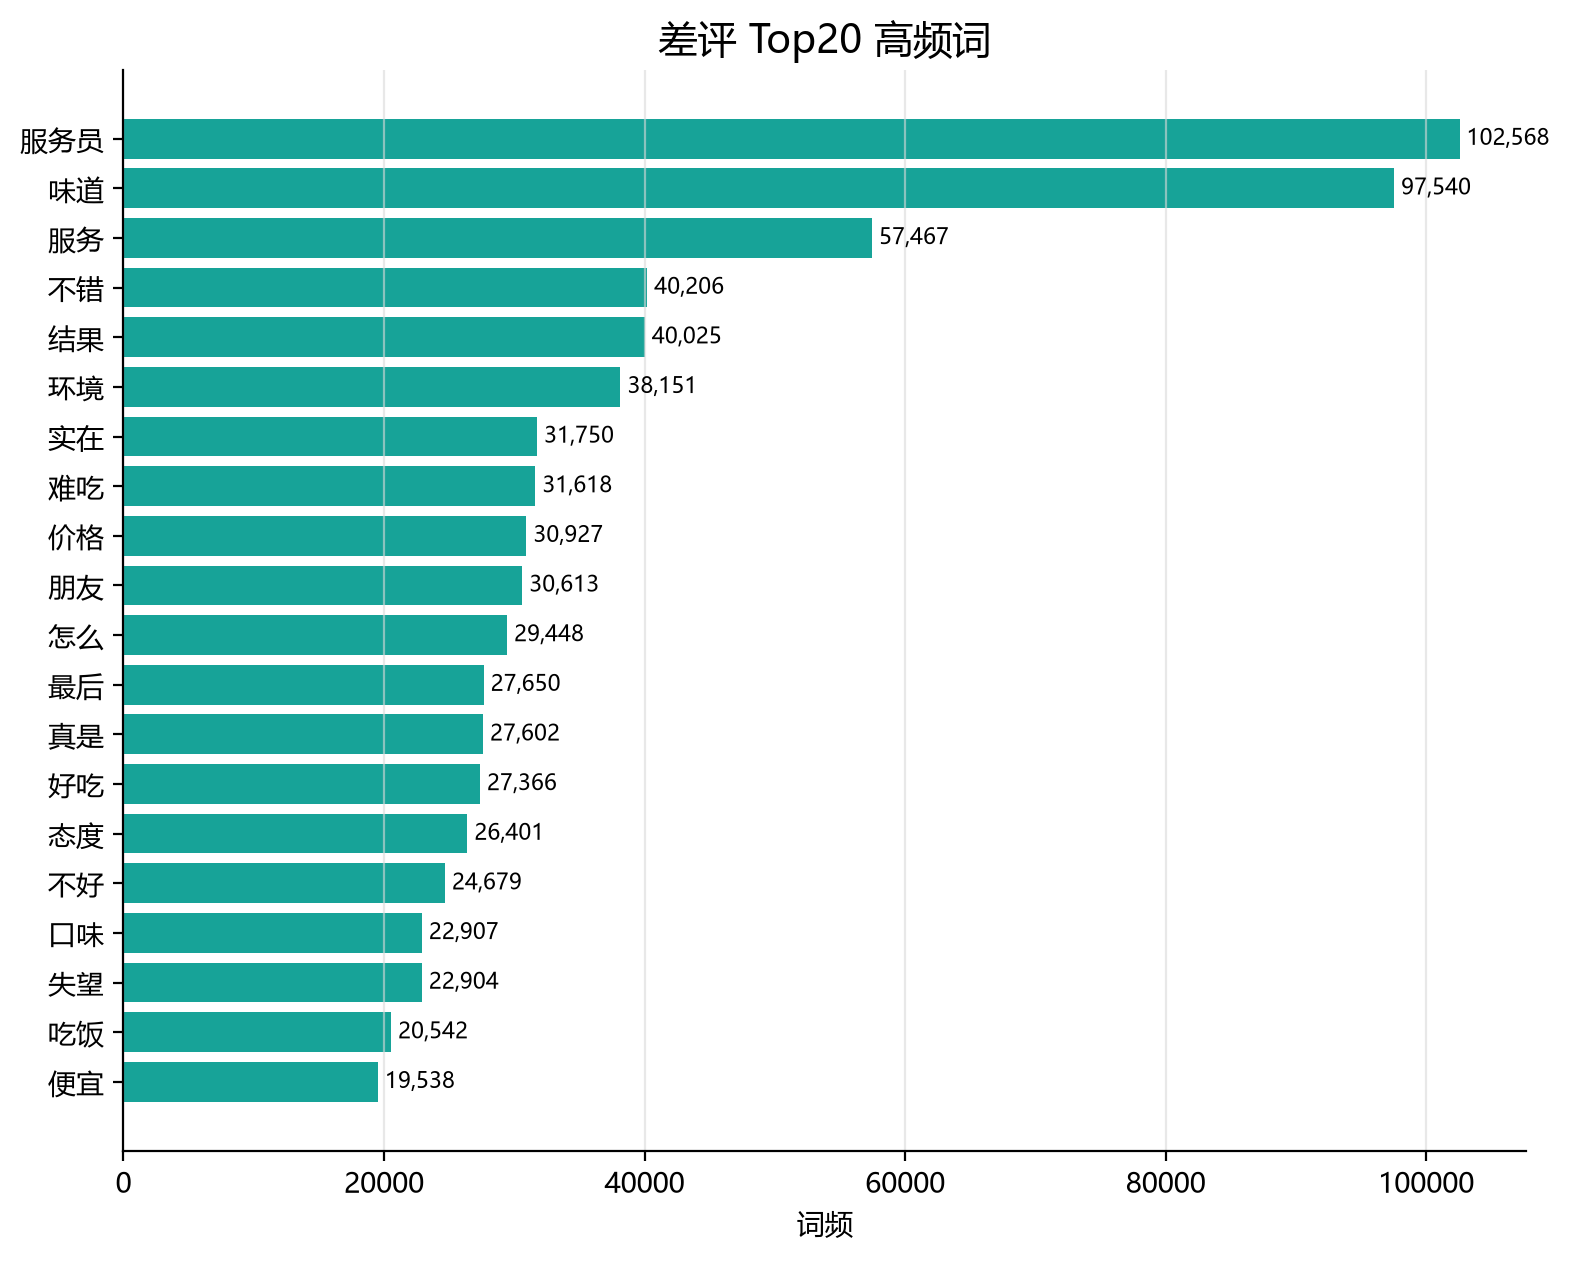

In [6]:
figs = []
figs.append(viz_utils.plot_top_words(cnt_all, "全部评论 Top20 高频词", "fig09_top20_all.png", color="#2e6f95"))
figs.append(viz_utils.plot_top_words(cnt_good, "好评 Top20 高频词", "fig09_top20_good.png", color="#e4572e"))
figs.append(viz_utils.plot_top_words(cnt_bad, "差评 Top20 高频词", "fig09_top20_bad.png", color="#17a398"))
for f in figs:
    display(Image(filename=str(f)))

In [7]:
# 好评 vs 差评 区分词（对数比 log-odds，取两边频次都 >= 1000 的词）
tot_g = sum(cnt_good.values()); tot_b = sum(cnt_bad.values())
words = [w for w in set(cnt_good) | set(cnt_bad)
         if cnt_good.get(w, 0) >= 1000 and cnt_bad.get(w, 0) >= 1000]
rows = []
for w in words:
    pg = cnt_good.get(w, 0) / tot_g
    pb = cnt_bad.get(w, 0) / tot_b
    rows.append((w, cnt_good.get(w, 0), cnt_bad.get(w, 0),
                 float(np.log((pg + 1e-12) / (pb + 1e-12)))))
cmp = pd.DataFrame(rows, columns=["词", "好评频次", "差评频次", "log_odds"]).sort_values("log_odds")
print("偏向差评的词 Top15:"); display(cmp.head(15))
print("偏向好评的词 Top15:"); display(cmp.tail(15).iloc[::-1])

偏向差评的词 Top15:


,词,好评频次,差评频次,log_odds
644,差劲,1023,4513,-3.322072
497,太差,1703,6870,-3.232622
1114,很差,3025,10295,-3.062597
854,恶心,2489,8224,-3.033025
555,垃圾,2240,6546,-2.910228
615,难吃,11766,31618,-2.826362
492,不新鲜,3687,9841,-2.819594
1134,无语,1940,5083,-2.801063
1017,生气,1054,2708,-2.781467
123,再也,4740,11487,-2.723028


偏向好评的词 Top15:


,词,好评频次,差评频次,log_odds
679,很好吃,203208,3585,2.199622
538,美味,61019,1713,1.735090
42,还会,48945,1411,1.708549
455,喜欢,657168,19235,1.693359
604,精致,41514,1374,1.570455
1132,机会,42128,1415,1.555734
284,不错,1159917,40206,1.524238
767,适合,116191,4064,1.515218
199,挺好吃,30557,1074,1.510354
235,实惠,88526,3358,1.434101


## 小结

- all 词云以「不错 / 味道 / 喜欢 / 环境 / 好吃 / 价格 / 服务员」为主，反映点评文本的通用维度；
- 好评词云偏「好吃 / 推荐 / 味道 / 服务 / 环境 / 划算」，差评词云偏「难吃 / 态度 / 服务员 / 贵 / 慢 / 失望」；
- 好评/差评 log-odds 对比表可直接用于报告"情感差异"分析。